# GPVS-Faults: exploratory data analysis

**EECE 490 — Fault Detection and Diagnosis in Grid-Connected Photovoltaic Systems**

Goal: understand the measurements, check quality and select a defensible initial
input schema **before** training. We use all 16 recordings for descriptive EDA;
therefore this is not a blind test-set analysis or evidence of predictive accuracy.
No fault onset, binary labels, learned feature selection, model or split is created here.

Source: [GPVS-Faults V1, CC BY 4.0](https://data.mendeley.com/datasets/n76t439f65/1),
Bakdi, Guichi, Mekhilef and Bounoua (2020), DOI 10.17632/n76t439f65.1.
`L` means IPPT, `M` means MPPT. F0 is documented fault-free; F1–F7 identify
recordings containing faults, not per-row labels. Their numbered mechanisms and
exact onsets remain unverified. See `reports/FEASIBILITY.md` for evidence gaps.

**Run:** select the project's `.venv` Python kernel and Run All in VS Code, or
run `.\.venv\Scripts\python.exe scripts/run_eda.py` from the repository root.
Figures are embedded below. Local PNG previews are generated under
`reports/figures/` and ignored by Git. Raw recordings are read directly from ZIP.

**Stage 4 update (29 October 2026):** the supplied original paper has now been
reviewed. F1-F7 mechanisms are verified in `annotations/recordings.csv` (paper
Table 1, p.7). The paper confirms nominal 100 microsecond sampling, describes
independent experiments, and explicitly says precise physical onset is unknown.
The EDA below preserves the earlier analysis and its outputs. References there
to unverified mechanisms are historical; onset uncertainty remains current.
See `reports/LABELING.md`. The estimated channels remain deferred provisionally,
not demonstrated to be unnecessary; the original paper uses them.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'scripts/gpvs_data.py').exists():
    ROOT = ROOT.parent  # support opening directly from notebooks/
assert (ROOT / 'scripts/gpvs_data.py').exists(), 'Open this notebook inside the project'
sys.path.insert(0, str(ROOT / 'scripts'))
from gpvs_data import load_recordings, model_input_view
FIGURES = ROOT / 'reports/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = {'IPPT': '#087f8c', 'MPPT': '#ce6a34'}
def mode(recording):
    return 'IPPT' if recording.endswith('L') else 'MPPT'
def finish(fig, filename):
    fig.savefig(FIGURES / filename, dpi=130, bbox_inches='tight')
    display(fig)
    plt.close(fig)

archive = ROOT / 'Data for EECE 490.zip'
initial_hash = hashlib.sha256(archive.read_bytes()).hexdigest()
recordings = load_recordings(archive)
policy = json.loads((ROOT / 'config/input_columns.json').read_text())
inputs = policy['measurement_inputs']
print(f'{len(recordings)} recordings; {sum(len(d) for d in recordings.values()):,} rows')
print('Python', platform.python_version(), '| NumPy', np.__version__,
      '| pandas', pd.__version__, '| Matplotlib', matplotlib.__version__)
display(recordings['F0L'].head())

16 recordings; 2,163,480 rows
Python 3.12.14 | NumPy 2.3.5 | pandas 3.0.1 | Matplotlib 3.10.7


,Time,Ipv,Vpv,Vdc,ia,ib,ic,va,vb,vc,Iabc,If,Vabc,Vf
0,0.000028,1.572327,101.348877,144.140625,-0.135133,0.490112,-0.354985,41.744537,-149.872894,109.064585,1.0,50.0,1.0,50.0
1,0.000128,1.503265,101.458740,143.554688,-0.108277,0.510254,-0.388555,46.831512,-150.716705,105.829976,1.0,50.0,1.0,50.0
2,0.000228,1.492859,101.574707,143.554688,-0.168702,0.496826,-0.334844,51.074677,-152.018585,102.543132,1.0,50.0,1.0,50.0
3,0.000328,1.558136,101.312256,143.261719,-0.135133,0.510254,-0.361699,55.848236,-152.585144,98.143260,1.0,50.0,1.0,50.0
4,0.000428,1.631927,101.141357,143.847656,-0.202271,0.503540,-0.321416,60.055237,-152.609253,94.261729,1.0,50.0,1.0,50.0


## 1. What does one row represent?

One row is a time sample, not an independent experiment. All tables contain
`Time` plus 13 signals. Ipv/Vpv/Vdc describe the PV/DC side; ia/ib/ic and va/vb/vc
describe the three phases. Iabc/Vabc and If/Vf are estimated magnitudes/frequencies.
Seconds are documented for Time. Current, voltage and frequency units are expected
to be A, V and Hz, but calibration and magnitude conventions still need verification.

We count recordings by scenario and mode. A cell with value **1** means there are
no repeated trials in that scenario/mode cell. A MAT/CSV pair is the same recording.

,scenario,mode,rows,columns,duration_s,fs_hz,dt_min_us,dt_median_us,dt_max_us,missing,nonfinite,duplicate_rows,nonpositive_time_steps,constant_columns
recording,,,,,,,,,,,,,,
F0L,F0,IPPT,143715,14,14.3699,10001.0113,85.3346,99.9969,100.2901,0,0,0,0,none
F0M,F0,MPPT,141014,14,14.0999,10001.0016,95.0117,99.9969,104.9820,0,0,0,0,none
F1L,F1,IPPT,129013,14,12.8999,10000.9915,82.9886,99.9969,118.7646,0,0,0,0,none
F1M,F1,MPPT,139014,14,13.8999,10001.0096,80.9359,99.9969,114.9524,0,0,0,0,none
F2L,F2,IPPT,142128,14,14.1999,10009.0148,93.5455,99.9969,117.8849,0,0,0,0,none
F2M,F2,MPPT,144015,14,14.4000,10001.0003,90.9062,99.9969,109.0875,0,0,0,0,none
F3L,F3,IPPT,103497,14,10.3486,10000.9922,92.0792,99.9969,108.5010,0,0,0,0,none
F3M,F3,MPPT,69967,14,6.9959,10001.0042,97.9441,99.9969,102.3428,0,0,0,0,none
F4L,F4,IPPT,144014,14,14.3999,10000.9765,50.4383,99.9969,146.9162,0,0,0,0,none


mode,IPPT,MPPT
scenario,,
F0,1,1
F1,1,1
F2,1,1
F3,1,1
F4,1,1
F5,1,1
F6,1,1
F7,1,1


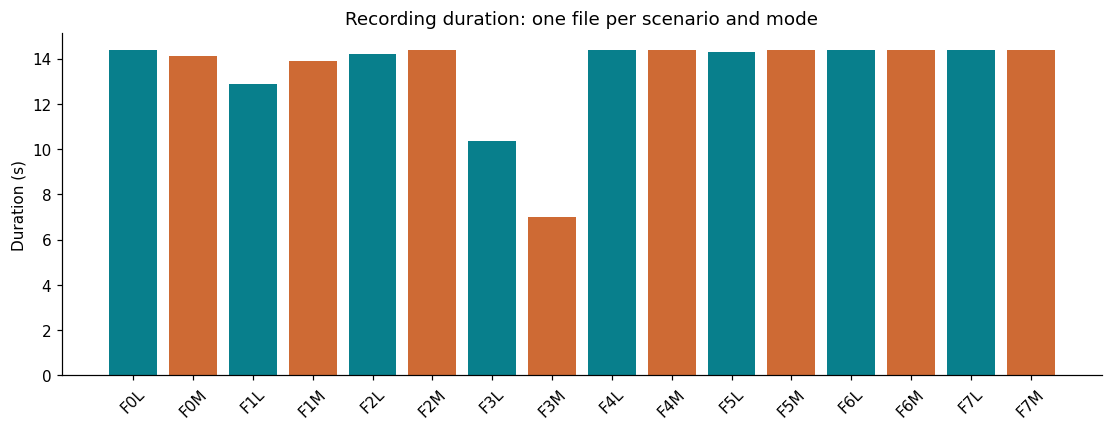

In [2]:
rows = []
for name, d in recordings.items():
    dt = np.diff(d.Time.to_numpy())
    rows.append({'recording': name, 'scenario': name[:2], 'mode': mode(name),
                 'rows': len(d), 'columns': len(d.columns),
                 'duration_s': d.Time.iloc[-1]-d.Time.iloc[0],
                 'fs_hz': 1/dt.mean(), 'dt_min_us': dt.min()*1e6,
                 'dt_median_us': np.median(dt)*1e6, 'dt_max_us': dt.max()*1e6,
                 'missing': int(d.isna().sum().sum()),
                 'nonfinite': int((~np.isfinite(d.to_numpy())).sum()),
                 'duplicate_rows': int(d.duplicated().sum()),
                 'nonpositive_time_steps': int((dt <= 0).sum()),
                 'constant_columns': ', '.join(d.columns[d.nunique() <= 1]) or 'none'})
overview = pd.DataFrame(rows).set_index('recording')
display(overview.round(4))
display(pd.crosstab(overview.scenario, overview['mode']))
fig, ax = plt.subplots(figsize=(10, 3.8), layout='constrained')
ax.bar(overview.index, overview.duration_s, color=[COLORS[m] for m in overview['mode']])
ax.set(title='Recording duration: one file per scenario and mode', ylabel='Duration (s)')
ax.tick_params(axis='x', rotation=45)
finish(fig, '01_recording_durations.png')

**Interpretation:** the corpus contains only a few minutes of signals. Large row
counts do not make it a large independent test set. Different recording lengths
must not become model features. F3 is shorter; length alone cannot explain why.

## 2. Data quality and timestamp spacing

Check missing/non-finite values, duplicates and constants before deciding on any
cleaning. Do not automatically remove extreme measurements: they may be the faults
we want to detect. A repeated scalar value can also be ordinary quantization.

,missing,nonfinite,duplicate_rows,nonpositive_time_steps,constant_columns
recording,,,,,
F0L,0,0,0,0,none
F0M,0,0,0,0,none
F1L,0,0,0,0,none
F1M,0,0,0,0,none
F2L,0,0,0,0,none
F2M,0,0,0,0,none
F3L,0,0,0,0,none
F3M,0,0,0,0,none
F4L,0,0,0,0,none


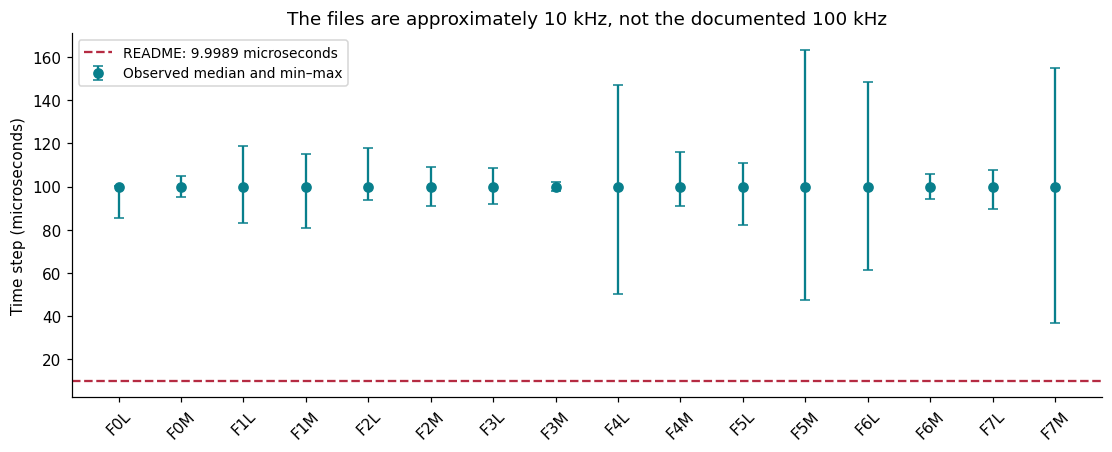

All parsed numeric types: ['float64']


In [3]:
display(overview[['missing', 'nonfinite', 'duplicate_rows',
                  'nonpositive_time_steps', 'constant_columns']])
fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
x = np.arange(len(overview))
med = overview.dt_median_us.to_numpy()
ax.errorbar(x, med, yerr=np.vstack([med-overview.dt_min_us, overview.dt_max_us-med]),
            fmt='o', color='#087f8c', capsize=3, label='Observed median and min–max')
ax.axhline(9.9989, color='#b52b42', linestyle='--', label='README: 9.9989 microseconds')
ax.set(xticks=x, xticklabels=overview.index, ylabel='Time step (microseconds)',
       title='The files are approximately 10 kHz, not the documented 100 kHz')
ax.tick_params(axis='x', rotation=45)
ax.legend(fontsize=9)
finish(fig, '02_timestamp_spacing.png')
print('All parsed numeric types:', sorted({str(t) for d in recordings.values() for t in d.dtypes}))

**Cleaning decision:** no missing-value imputation, duplicate-row removal or
constant-column removal is currently necessary. Retain the observed time axis;
there are occasional irregular steps. Do not rescale it to match the README.

## 3. How do signals change during each recording?

The next figure shows Vdc for every recording. To make long signals legible,
each display block contains about 100 samples: the line is the median and shading
is the full min–max range. This is **plotting only**, not smoothing for a model.
There are deliberately no midpoint fault labels. A visible change is not a verified
injection time. Units below follow expected physical units pending confirmation.

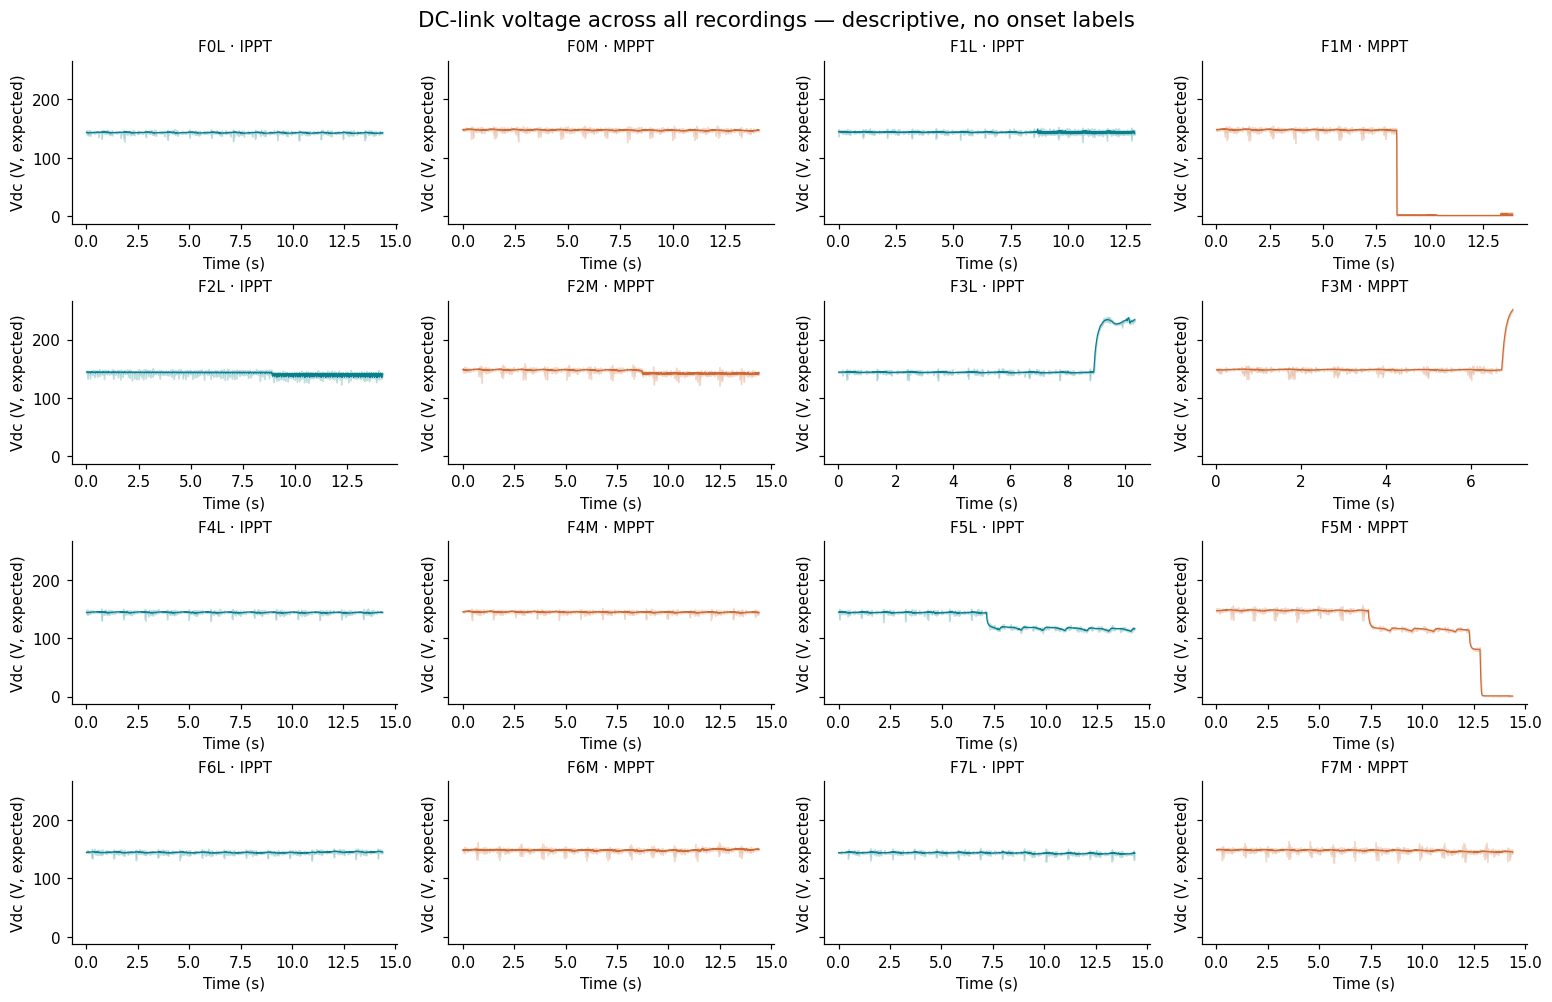

In [4]:
fig, axes = plt.subplots(4, 4, figsize=(14, 9), sharey=True, layout='constrained')
for ax, (name, d) in zip(axes.flat, recordings.items()):
    block = np.arange(len(d)) // 100
    grouped = d[['Time', 'Vdc']].groupby(block)
    t = grouped.Time.mean().to_numpy()
    band = grouped.Vdc.agg(['min', 'median', 'max'])
    color = COLORS[mode(name)]
    ax.fill_between(t, band['min'], band['max'], color=color, alpha=.23)
    ax.plot(t, band['median'], color=color, linewidth=.8)
    ax.set_title(f'{name} · {mode(name)}', fontsize=10)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Vdc (V, expected)')
fig.suptitle('DC-link voltage across all recordings — descriptive, no onset labels', fontsize=14)
finish(fig, '03_dc_voltage_all_recordings.png')

## 4. Three-phase waveforms in documented normal recordings

View a short interval without downsampling to see actual oscillations. We use the
same 0.20–0.24 s interval in F0L and F0M for illustration, not as a matched trial
or an estimate of the causal effect of operating mode.

**Observed pattern:** Vdc drops sharply in F1M and in stages in F5M, while F3L/F3M rise late in their recordings. Several other traces have much smaller changes. This suggests that one large-voltage-change rule may not cover every scenario. These visible transitions are not verified fault onset labels.

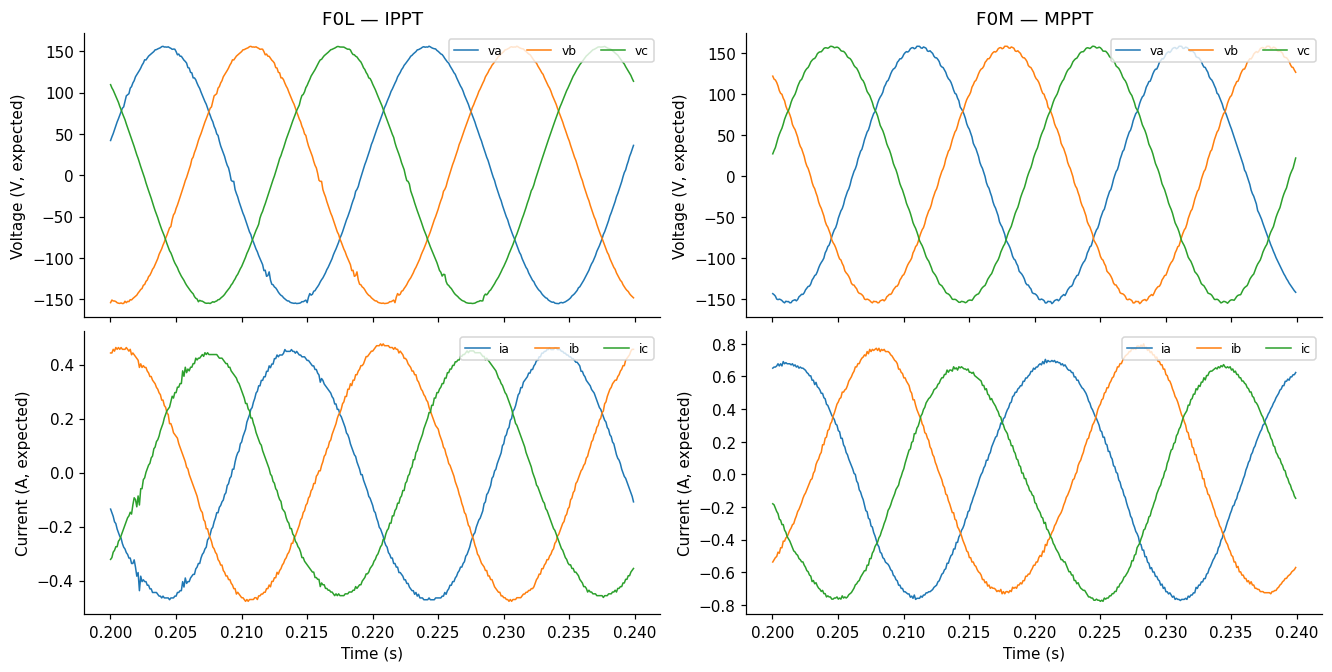

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, layout='constrained')
for j, name in enumerate(['F0L', 'F0M']):
    d = recordings[name]
    segment = d.loc[d.Time.between(.20, .24)]
    for c in ['va', 'vb', 'vc']:
        axes[0, j].plot(segment.Time, segment[c], label=c, linewidth=1)
    for c in ['ia', 'ib', 'ic']:
        axes[1, j].plot(segment.Time, segment[c], label=c, linewidth=1)
    axes[0, j].set_title(f'{name} — {mode(name)}')
    axes[0, j].set_ylabel('Voltage (V, expected)')
    axes[1, j].set_ylabel('Current (A, expected)')
    axes[1, j].set_xlabel('Time (s)')
    for ax in axes[:, j]:
        ax.legend(loc='upper right', fontsize=8, ncol=3)
finish(fig, '04_normal_phase_waveforms.png')

## 5. Distributions by recording and mode

Each point is one recording's median, with its 25th–75th percentile range.
Statistics use all rows; every recording occupies one position on the plot.
For F1–F7 the summary mixes pre-injection, transition and later operation.
It is **not** a fault-class distribution. Oscillating phase voltages/currents can
have medians near zero even when their amplitudes are large.

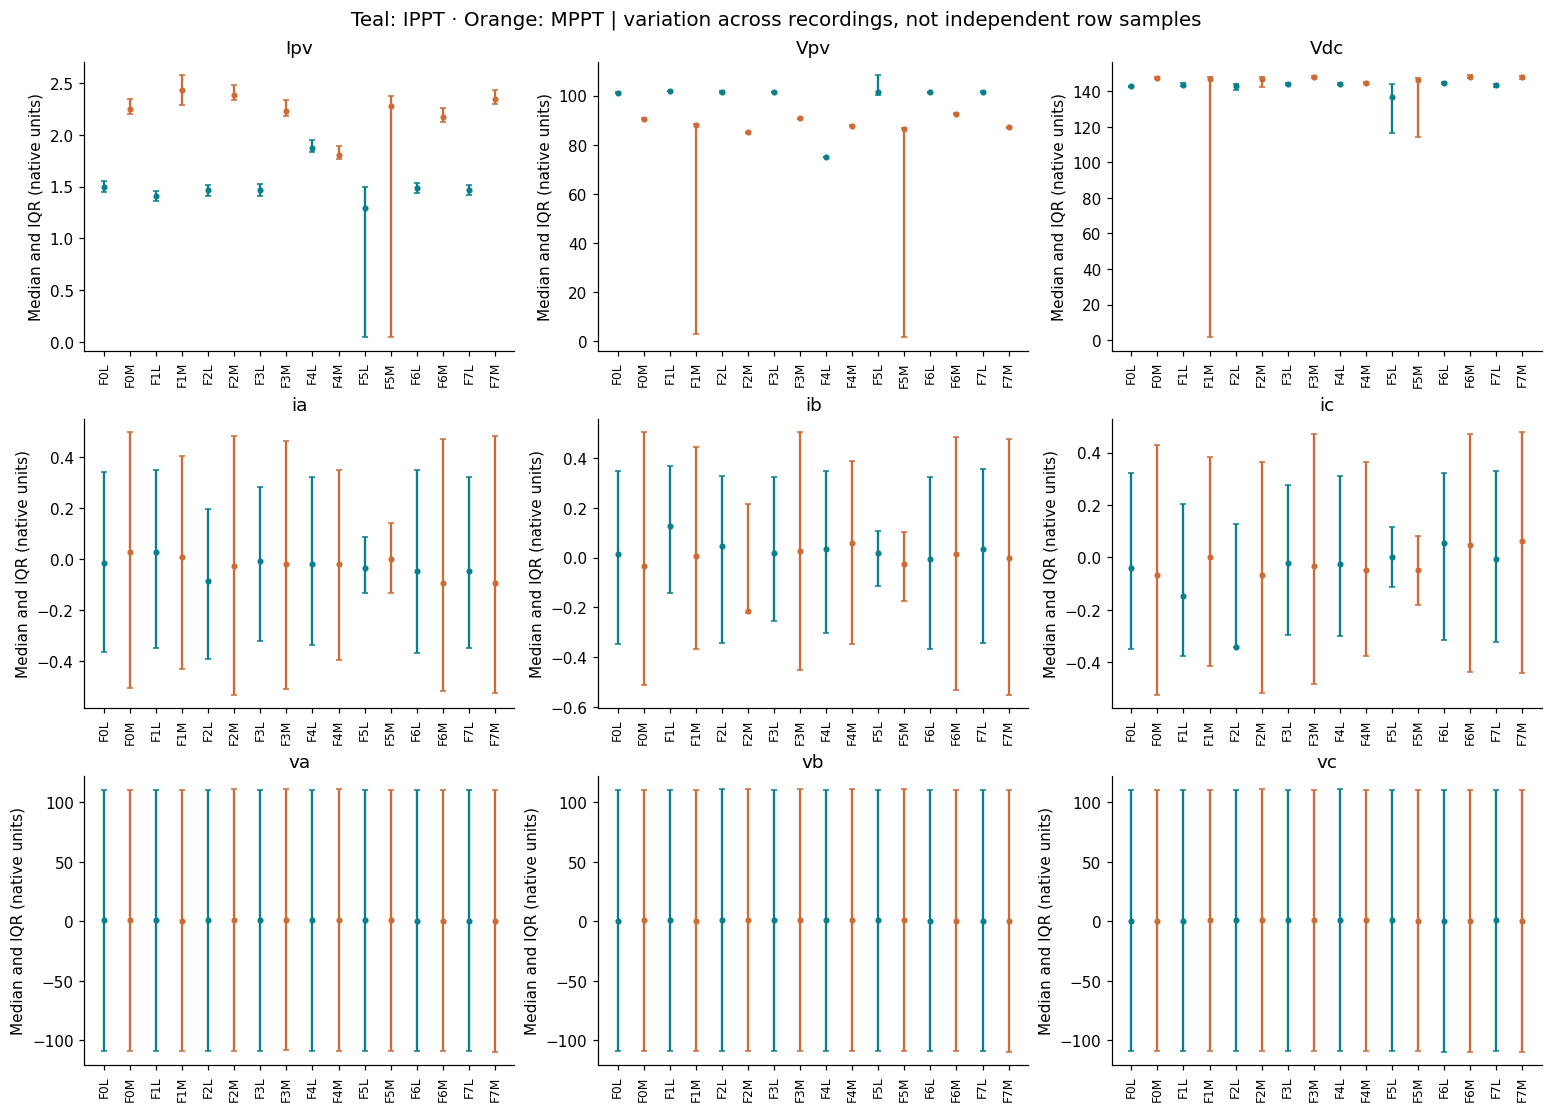

,min,max
channel,,
Ipv,-0.595062,11.208740
Vpv,-16.558838,111.474609
Vdc,0.000000,253.710938
ia,-6.358888,13.769286
ib,-7.297974,6.828003
ic,-12.856206,6.358882
va,-162.204590,161.204071
vb,-162.204590,161.204071
vc,-160.034790,160.211589


In [6]:
summary = []
for name, d in recordings.items():
    for c in inputs:
        q = d[c].quantile([0, .25, .5, .75, 1])
        summary.append({'recording': name, 'mode': mode(name), 'channel': c,
                        'min': q.iloc[0], 'q25': q.iloc[1], 'median': q.iloc[2],
                        'q75': q.iloc[3], 'max': q.iloc[4]})
distribution = pd.DataFrame(summary)
fig, axes = plt.subplots(3, 3, figsize=(14, 10), layout='constrained')
for ax, c in zip(axes.flat, inputs):
    s = distribution.loc[distribution.channel == c]
    for j, (_, row) in enumerate(s.iterrows()):
        ax.errorbar(j, row['median'], yerr=[[row['median']-row.q25], [row.q75-row['median']]],
                    fmt='o', markersize=3, capsize=2, color=COLORS[row['mode']])
    ax.set(xticks=range(16), xticklabels=s.recording, title=c,
           ylabel='Median and IQR (native units)')
    ax.tick_params(axis='x', rotation=90, labelsize=8)
fig.suptitle('Teal: IPPT · Orange: MPPT | variation across recordings, not independent row samples', fontsize=13)
finish(fig, '05_channel_distributions.png')
display(distribution.groupby('channel', sort=False)[['min', 'max']].agg({'min':'min', 'max':'max'}))

## 6. Correlation: related does not mean unnecessary

For initial diagnostics, use the two documented fault-free recordings separately.
Pearson correlation measures same-time linear relationships. Phase shifts can create
strong correlations even when all three phases matter for imbalance analysis.
Pooling fault scenarios can additionally make correlations reflect scenario mixture.
These plots do not justify learned feature elimination or prove predictor usefulness.

**Observed pattern:** many MPPT recordings have higher typical Ipv and lower typical Vpv than IPPT recordings. F4 and fault-containing intervals complicate that pattern. A global threshold could confuse operating-condition differences with faults, so future comparisons must examine each mode. These recordings are not controlled matched trials.

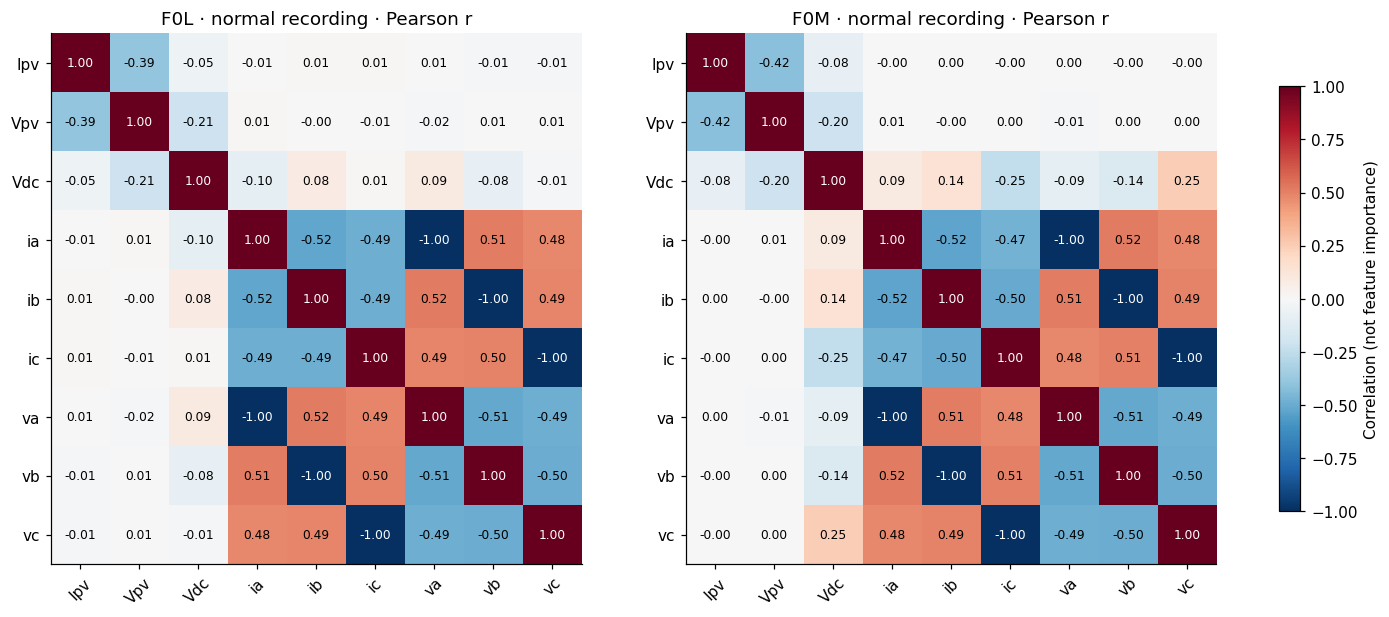

,recording,max_abs_va_plus_vb_plus_vc,max_abs_ia_plus_ib_plus_ic
0,F0L,12.737528,0.416254
1,F0M,12.604930,0.604254
2,F1L,16.406097,0.429682
3,F1M,12.878164,1.101080
4,F2L,13.545176,1.725470
5,F2M,13.468831,1.685187
6,F3L,30.172272,0.483393
7,F3M,16.920420,0.449835
8,F4L,12.219187,0.537104
9,F4M,12.082570,0.543829


Exactly duplicated measurement columns across every recording: []


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout='constrained')
for ax, name in zip(axes, ['F0L', 'F0M']):
    corr = recordings[name][inputs].corr()
    image = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set(xticks=range(9), yticks=range(9), xticklabels=inputs, yticklabels=inputs,
           title=f'{name} · normal recording · Pearson r')
    ax.tick_params(axis='x', rotation=45)
    for i in range(9):
        for j in range(9):
            value = corr.iloc[i, j]
            ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if abs(value) > .65 else 'black')
fig.colorbar(image, ax=axes, shrink=.8, label='Correlation (not feature importance)')
finish(fig, '06_normal_correlations.png')

phase_checks = []
for name, d in recordings.items():
    phase_checks.append({'recording': name,
                         'max_abs_va_plus_vb_plus_vc': d[['va','vb','vc']].sum(axis=1).abs().max(),
                         'max_abs_ia_plus_ib_plus_ic': d[['ia','ib','ic']].sum(axis=1).abs().max()})
display(pd.DataFrame(phase_checks).round(6))
exact_duplicates = []
for i, a in enumerate(inputs):
    for b in inputs[i+1:]:
        if all(np.array_equal(d[a].to_numpy(), d[b].to_numpy()) for d in recordings.values()):
            exact_duplicates.append((a, b))
print('Exactly duplicated measurement columns across every recording:', exact_duplicates)

**Decision:** retain all nine measured signals. Neither constant nor exact duplicate
columns were found. The phase sums are not identically zero, so discarding one phase
and reconstructing it from the other two would change the data. A phase sum here is
not a verified ground-current measurement. Evaluate any learned redundancy reduction
only within future training folds, and compare its effect on held-out recordings.

**Observed pattern:** same-phase current and voltage are strongly negatively correlated in the two normal recordings; values displayed as -1.00 are rounded, not proof of exact duplication. Their relationship can change during faults, and voltage/current amplitudes carry different physical information. Keep both measurements.

## 7. Why defer the four estimated channels?

We inspect their first 50 ms and count identical initial values in every recording.
This checks a plausible estimator warm-up artifact; it does not assume these features
are useless. Their latency and causal implementation are currently unknown.

,recording,Iabc_initial_value,Iabc_initial_run_samples,If_initial_value,If_initial_run_samples,Vabc_initial_value,Vabc_initial_run_samples,Vf_initial_value,Vf_initial_run_samples
0,F0L,1.0,201,50.0,204,1.0,201,50.0,204
1,F0M,1.0,201,50.0,204,1.0,201,50.0,204
2,F1L,1.0,201,50.0,204,1.0,201,50.0,204
3,F1M,1.0,201,50.0,204,1.0,201,50.0,204
4,F2L,1.0,201,50.0,204,1.0,201,50.0,204
5,F2M,1.0,201,50.0,204,1.0,201,50.0,204
6,F3L,1.0,201,50.0,204,1.0,201,50.0,204
7,F3M,1.0,201,50.0,204,1.0,201,50.0,204
8,F4L,1.0,201,50.0,204,1.0,201,50.0,204
9,F4M,1.0,201,50.0,204,1.0,201,50.0,204


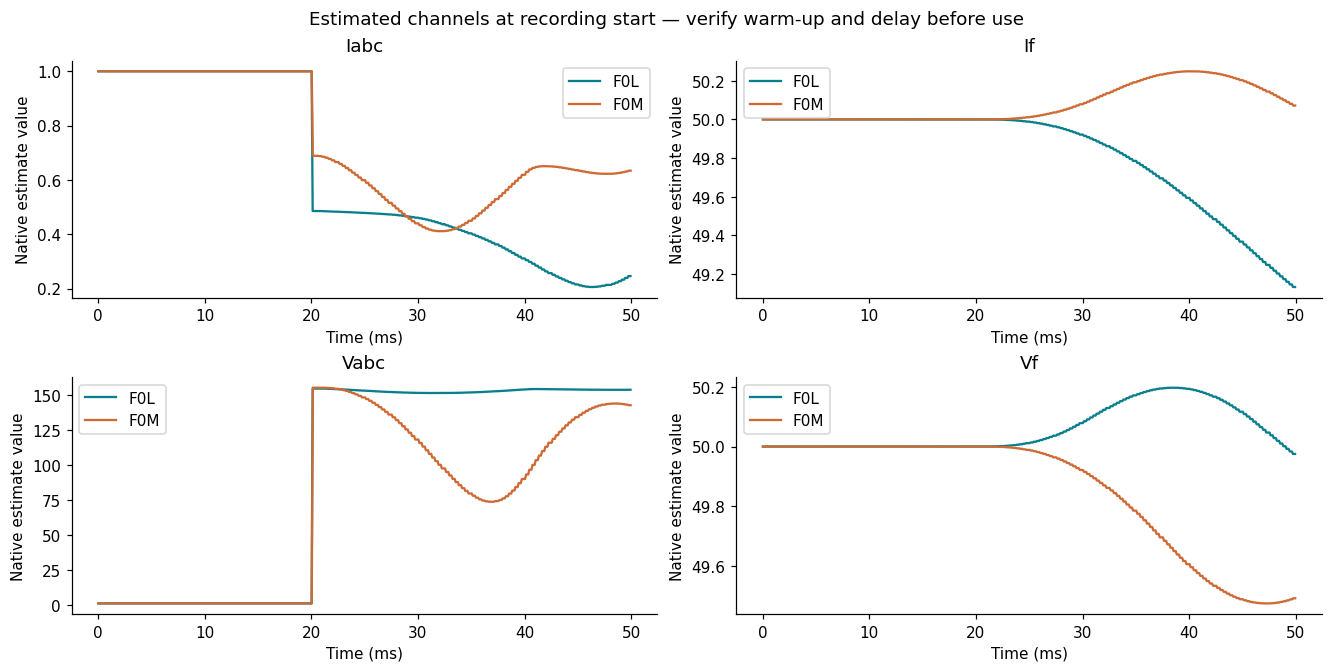

In [8]:
startup = []
for name, d in recordings.items():
    row = {'recording': name}
    for c in policy['deferred_estimates']:
        x = d[c].to_numpy()
        changes = np.flatnonzero(x != x[0])
        row[c + '_initial_value'] = x[0]
        row[c + '_initial_run_samples'] = int(changes[0]) if len(changes) else len(x)
    startup.append(row)
display(pd.DataFrame(startup))
fig, axes = plt.subplots(2, 2, figsize=(12, 6), layout='constrained')
for ax, c in zip(axes.flat, policy['deferred_estimates']):
    for name in ['F0L', 'F0M']:
        d = recordings[name].loc[lambda d: d.Time <= .05]
        ax.plot(d.Time*1000, d[c], label=name, color=COLORS[mode(name)])
    ax.set(title=c, xlabel='Time (ms)', ylabel='Native estimate value')
    ax.legend()
fig.suptitle('Estimated channels at recording start — verify warm-up and delay before use')
finish(fig, '07_estimator_startup.png')

## 8. Apply the provisional input-column decision

This is input schema selection, not a trained feature selector. Later, we will derive
causal features such as RMS from these measurements after assigning recording groups.

| Role | Columns | Reason |
| --- | --- | --- |
| Keep as initial measured inputs | Ipv, Vpv, Vdc, ia, ib, ic, va, vb, vc | Different physical information; no demonstrated dispensable measurement |
| Keep separately, exclude from predictors | Time | Needed for timing/windows; absolute experiment time can become an onset shortcut |
| Defer from initial predictors | Iabc, If, Vabc, Vf | Estimated channels with initialization plateaus and unverified delay |
| Grouping metadata only | Recording ID, scenario, mode | Scenario is not a per-row label; filenames must never become predictors |

The original 14 columns remain intact. We do not clip outliers, drop fault-like rows,
remove normal prefixes, rescale timestamps or create a large duplicate cleaned dataset.
The configuration and loader reproduce the nine-column view whenever needed.

In [9]:
sample = recordings['F0L']
X_example = model_input_view(sample)
time_example = sample['Time'].copy()
assert X_example.columns.tolist() == inputs and X_example.shape == (len(sample), 9)
assert len(sample.columns) == 14
assert 'Time' not in X_example and not set(policy['deferred_estimates']) & set(X_example)
for name, raw in recordings.items():
    selected = model_input_view(raw)
    assert selected.index.equals(raw.index)
    assert np.array_equal(selected.to_numpy(), raw[inputs].to_numpy())
# Prove that editing the model view cannot alter the raw frame.
old_value = sample['Ipv'].iloc[0]
X_example.iloc[0, 0] = old_value + 1
assert sample['Ipv'].iloc[0] == old_value
X_example = model_input_view(sample)
assert hashlib.sha256(archive.read_bytes()).hexdigest() == initial_hash
print('Verified every input view: same rows and values, nine columns, raw archive unchanged.')
display(X_example.head())

Verified every input view: same rows and values, nine columns, raw archive unchanged.


,Ipv,Vpv,Vdc,ia,ib,ic,va,vb,vc
0,1.572327,101.348877,144.140625,-0.135133,0.490112,-0.354985,41.744537,-149.872894,109.064585
1,1.503265,101.458740,143.554688,-0.108277,0.510254,-0.388555,46.831512,-150.716705,105.829976
2,1.492859,101.574707,143.554688,-0.168702,0.496826,-0.334844,51.074677,-152.018585,102.543132
3,1.558136,101.312256,143.261719,-0.135133,0.510254,-0.361699,55.848236,-152.585144,98.143260
4,1.631927,101.141357,143.847656,-0.202271,0.503540,-0.321416,60.055237,-152.609253,94.261729


## Findings and next stage

- **Data quality:** no missing/non-finite values, repeated complete rows or constant
  columns were found. No row deletion or imputation is justified by these checks.
- **Sampling:** observed spacing is about 100 microseconds (~10 kHz), not the
  README's roughly 10 microseconds. Preserve and investigate irregular timing.
- **Coverage:** one recording per scenario/mode. Keep recordings together when
  eventually splitting; never randomly split waveform rows or overlapping windows.
- **Inputs:** nine measured channels retained, Time separated, four estimates
  deferred. This does not claim that the selected schema is prediction-optimal.
- **Labels:** F1–F7 contain unknown transition times. Do not assign the entire file
  its fault state or automatically split it at its midpoint.
- **Next:** verify mechanisms/onset intervals and finalize groups, then compare
  causal features, rules and ML. Use development folds for any further selection.
  Full-corpus EDA has been performed and must be disclosed in the final report.

No accuracy, fault detection delay or ML superiority has been measured here.